# AgriOptima: Soil clustering

K-means groups similar soil records without a known target label. Select the number of clusters on training locations. Cluster IDs are arbitrary and do not represent healthy/unhealthy soil.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
features = ['depth_top_cm', 'depth_bottom_cm', 'ph_h2o', 'organic_carbon_g_kg',
            'total_nitrogen_g_kg', 'sand_pct', 'silt_pct', 'clay_pct',
            'bulk_density_g_cm3', 'cec_cmol_kg', 'coarse_fragments_vol_pct']
location = ['latitude', 'longitude']
samples = []
# Read one depth file at a time. Sample equally so every depth is represented.
for path in sorted((ROOT / 'DataSets/Soil Grid').glob('soilgrids_*.csv')):
    frame = pd.read_csv(path)
    for column in features + location:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    valid = np.isfinite(frame[features + location]).all(axis=1)
    frame = frame.loc[valid]
    sample = frame.sample(min(5000, len(frame)), random_state=42).copy()
    sample['source_depth_file'] = path.name
    samples.append(sample)
data = pd.concat(samples, ignore_index=True)
data = data.drop_duplicates(subset=location + ['depth_top_cm', 'depth_bottom_cm'])
print('Prepared soil rows:', len(data))
display(data.head())

Prepared soil rows: 30000


,latitude,longitude,depth_top_cm,depth_bottom_cm,ph_h2o,organic_carbon_g_kg,total_nitrogen_g_kg,sand_pct,silt_pct,clay_pct,bulk_density_g_cm3,cec_cmol_kg,coarse_fragments_vol_pct,source_depth_file
0,29.228952,76.748659,0,5,8.8,11.2,1.25,36.1,33.7,30.3,1.42,13.7,7.5,soilgrids_0-5cm.csv
1,32.536305,75.356020,0,5,6.4,47.1,3.77,34.8,40.5,24.7,1.31,20.8,10.4,soilgrids_0-5cm.csv
2,30.853952,77.218901,0,5,6.0,46.2,4.68,38.6,37.6,23.7,1.18,21.0,20.8,soilgrids_0-5cm.csv
3,27.632629,77.454022,0,5,8.2,7.8,1.22,41.1,31.8,27.1,1.46,13.6,6.8,soilgrids_0-5cm.csv
4,29.286305,77.038039,0,5,8.7,10.7,1.15,38.9,34.4,26.7,1.42,13.9,5.5,soilgrids_0-5cm.csv


### Look at the data
This overview describes the dataset. It is not a prediction result.

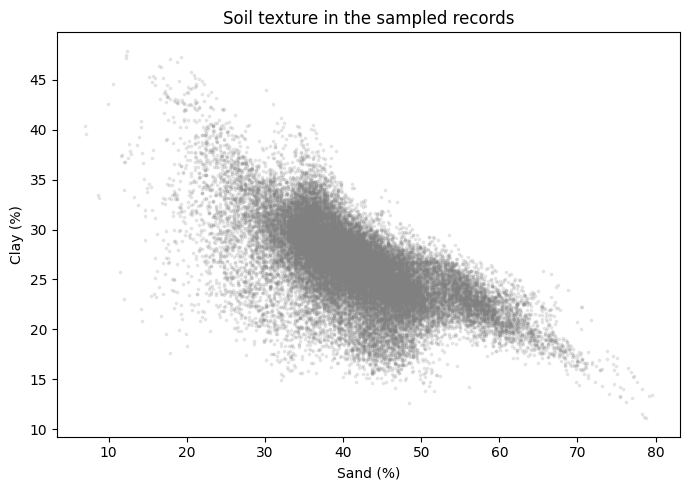

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(data['sand_pct'], data['clay_pct'], s=3, alpha=0.15, color='gray')
plt.xlabel('Sand (%)')
plt.ylabel('Clay (%)')
plt.title('Soil texture in the sampled records')
plt.tight_layout()
plt.show()

Each dot is a soil record at a location and depth. Sand and clay help describe soil texture. The clustering model uses all selected properties, not only these two.

## 3. Prepare inputs, split data, train and evaluate
X contains measurements; y contains known answers in supervised tasks. Fit preprocessing on training rows only. Keep time order for prices/yield and keep soil locations together.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [5]:
features = [
    "depth_top_cm",
    "depth_bottom_cm",
    "ph_h2o",
    "organic_carbon_g_kg",
    "total_nitrogen_g_kg",
    "sand_pct",
    "silt_pct",
    "clay_pct",
    "bulk_density_g_cm3",
    "cec_cmol_kg",
    "coarse_fragments_vol_pct",
]

In [6]:
# 2. All depths from one location must stay in the same partition.
groups = (
    data["latitude"].round(5).astype(str) + "|" + data["longitude"].round(5).astype(str)
)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_indices, test_indices = next(splitter.split(data, groups=groups))
train = data.iloc[train_indices]
test = data.iloc[test_indices]

In [7]:
# 3. Learn missing-value replacements and scales from training measurements only.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train = imputer.fit_transform(train[features])
X_train = scaler.fit_transform(X_train)
X_test = imputer.transform(test[features])
X_test = scaler.transform(X_test)

In [8]:
# 4. Try 2 to 5 groups. Select k using training data only.
best_k = None
best_score = -float("inf")
for k in [2, 3, 4, 5]:
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    candidate.fit(X_train)
    score = silhouette_score(
        X_train, candidate.labels_, sample_size=min(2000, len(X_train)), random_state=42
    )
    print("Groups:", k, "Training silhouette:", score)
    if score > best_score:
        best_score = score
        best_k = k

/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_wei

/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/

Groups: 2 Training silhouette: 0.380334423717003
Groups: 3 Training silhouette: 0.25493109337883973
Groups: 4 Training silhouette: 0.23109018397196024


Groups: 5 Training silhouette: 0.24478162229583778


/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_wei

In [9]:
# 5. Fit the selected model and assign held-out soil rows to groups.
model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
model.fit(X_train)
groups_predicted = model.predict(X_test)
print("Selected number of groups:", best_k)
print(
    "Test silhouette:",
    silhouette_score(
        X_test, groups_predicted, sample_size=min(2000, len(X_test)), random_state=42
    ),
)
# Silhouette describes separation. Group 0 does not mean bad soil or a crop recommendation.

Selected number of groups: 2
Test silhouette: 0.3909856643417678


/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_wei

## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

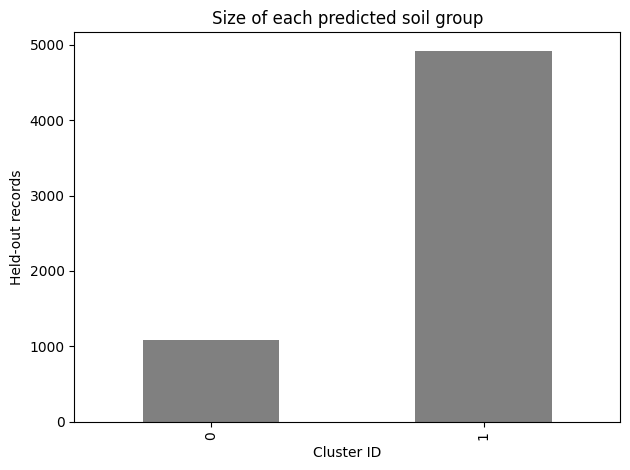

In [10]:
pd.Series(groups_predicted).value_counts().sort_index().plot.bar(color='gray')
plt.xlabel('Cluster ID')
plt.ylabel('Held-out records')
plt.title('Size of each predicted soil group')
plt.tight_layout()
plt.show()

Bars count records in each group. A bigger group is more common in this sample; it is not necessarily better soil. Silhouette measures geometric separation.

## 5. Save this learning model separately
The working application models remain unchanged. The saved bundle includes the features and preprocessing needed for later use. This is the holdout experiment model, not an all-data production refit.

In [11]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'imputer': imputer, 'scaler': scaler, 'features': features}
joblib.dump(bundle, output / '05_soil_clustering.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
K-means groups similar soil records without a known target label. Select the number of clusters on training locations. Cluster IDs are arbitrary and do not represent healthy/unhealthy soil.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.